# Exploratory data analysis: loan-month prepayment data

What drives a loan to be prepaid in a given month, and what does the data imply for the models in `src/models.py`?

This notebook explores the **synthetic** loan-month panel that `python -m src.train --data synthetic` trains on (3,000 loans, Freddie Mac schema). For the real data, replace `make_synthetic(3000)` with `load_freddie("../data/freddie", "../data/macro.csv")` from `src.data`; every cell below works unchanged.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))  # the notebook lives in notebooks/; import the project's src package
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.data import NUM, make_synthetic

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
df = make_synthetic(3000)  # exactly the data used by `python -m src.train --data synthetic`
print(f"{len(df):,} loan-month rows from {df.loan_id.nunique():,} loans, {len(NUM)} numeric + 3 categorical features")
df.head()

200,911 loan-month rows from 3,000 loans, 14 numeric + 3 categorical features


,loan_id,prepaid,credit_score,dti,ltv,cltv,orig_upb,orig_interest_rate,loan_age,current_upb,months_to_maturity,current_interest_rate,mtg_rate,rate_incentive,hpi_change,unemployment,occupancy_status,loan_purpose,channel
0,0,0,769,32.755621,85.715328,87.011163,385198.832575,4.965847,1,385198.832575,359,4.965847,4.956382,0.009464,2.424491,4.857240,P,N,B
1,0,0,769,32.755621,85.715328,86.591762,385198.832575,4.965847,2,384733.066699,358,4.965847,4.835492,0.130354,6.449335,3.000000,P,N,B
2,0,0,769,32.755621,85.715328,87.492572,385198.832575,4.965847,3,384265.373388,357,4.965847,4.741091,0.224755,-2.418862,4.741050,P,N,B
3,0,0,769,32.755621,85.715328,85.910483,385198.832575,4.965847,4,383795.744666,356,4.965847,4.802818,0.163029,4.366657,4.969129,P,N,B
4,0,0,769,32.755621,85.715328,86.081443,385198.832575,4.965847,5,383324.172523,355,4.965847,4.720787,0.245059,6.842319,6.582068,P,N,B


## 1. Class balance
One row is one loan in one month; the label is 1 only in the month the loan is paid off.

prepaid loan-months : 2,944 of 200,911  (1.47%)  ->  imbalance 1:67
accuracy of always predicting 'no prepayment': 98.53%
loans that prepay at some point: 98.1%
median months observed per loan: 42


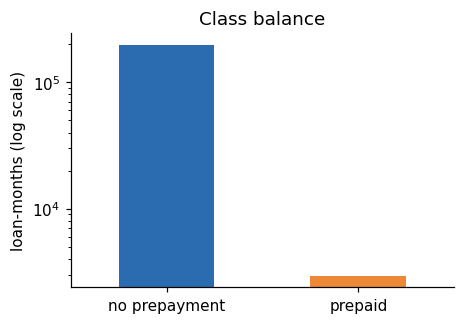

In [2]:
rate = df.prepaid.mean()
print(f"prepaid loan-months : {df.prepaid.sum():,} of {len(df):,}  ({rate:.2%})  ->  imbalance 1:{(1 - rate) / rate:.0f}")
print(f"accuracy of always predicting 'no prepayment': {1 - rate:.2%}")
print(f"loans that prepay at some point: {df.groupby('loan_id').prepaid.max().mean():.1%}")
print(f"median months observed per loan: {df.groupby('loan_id').size().median():.0f}")

ax = df.prepaid.map({0: "no prepayment", 1: "prepaid"}).value_counts().plot.bar(
    color=["#2b6cb0", "#ed8936"], logy=True, rot=0, figsize=(4.5, 3))
ax.set_xlabel(""); ax.set_ylabel("loan-months (log scale)"); ax.set_title("Class balance");

In [3]:
def prepay_rate(col, bins):
    """Monthly prepayment rate (%) and number of loan-months in each bin of `col`."""
    g = df.groupby(pd.cut(df[col], bins), observed=True).prepaid
    return pd.DataFrame({"loan_months": g.size(), "prepay_rate_%": (100 * g.mean()).round(2)})


def bar(t, xlabel, ax=None):
    ax = t["prepay_rate_%"].plot.bar(color="#2b6cb0", rot=30, ax=ax, figsize=None if ax else (6, 3))
    ax.set_ylabel("monthly prepayment rate (%)"); ax.set_xlabel(xlabel)
    return ax

**Heavy imbalance.** Only 1.47% of loan-months are prepayments (1:67), so a model that never predicts a prepayment is already 98.53% accurate. This is why the project reports precision, recall, F1 and PR-AUC instead of accuracy, and tunes each decision threshold on the validation split.

Almost every synthetic loan (98.1%) prepays at some point within its 30 years; in the real Freddie Mac data many loans are still active at the data cut-off, so the real panel is even more imbalanced.

## 2. Refinancing incentive
`rate_incentive` = the loan's interest rate minus the current market mortgage rate. A positive value means the borrower could refinance into a cheaper loan.

                loan_months  prepay_rate_%
rate_incentive                            
(-4.0, -1.0]          22547           0.07
(-1.0, -0.5]          29467           0.23
(-0.5, 0.0]           53813           0.54
(0.0, 0.5]            56982           1.39
(0.5, 1.0]            28792           3.26
(1.0, 1.5]             8029           7.88
(1.5, 2.5]             1281          16.16


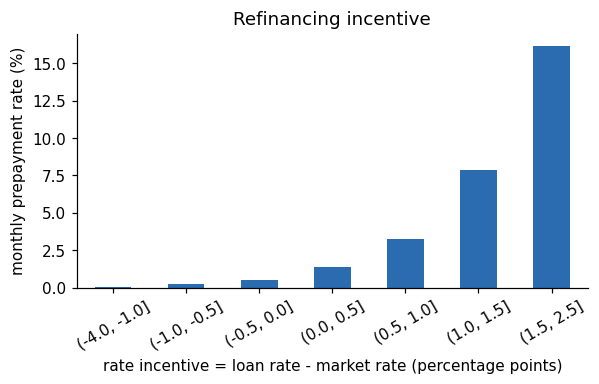

In [4]:
inc = prepay_rate("rate_incentive", [-4, -1, -0.5, 0, 0.5, 1, 1.5, 2.5])
print(inc.to_string())
bar(inc, "rate incentive = loan rate - market rate (percentage points)").set_title("Refinancing incentive");

**The strongest driver by far.** The monthly prepayment rate rises monotonically with the incentive: from 0.07% when the loan is more than 1 point *below* market, through 1.39% around zero, to 16.16% when it is 1.5 to 2.5 points *above* market, a roughly 230x difference. This matches finance theory (borrowers refinance when rates fall) and is why `rate_incentive` is the top feature of the L1 logistic model. Most loan-months (about 111k of 201k) sit within half a point of the market rate, where the signal is weak, which caps how well any model can do.

## 3. Loan age (seasoning)

            loan_months  prepay_rate_%
loan_age                              
(0, 6]            17575           0.98
(6, 12]           16441           1.36
(12, 24]          28844           1.58
(24, 36]          23270           1.99
(36, 60]          32779           1.84
(60, 120]         41320           1.57
(120, 240]        29747           1.01
(240, 360]        10935           0.70


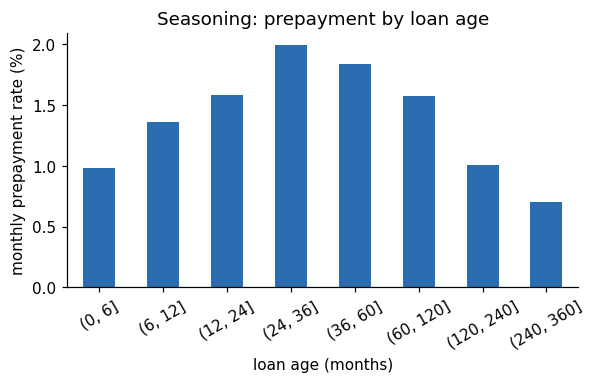

In [5]:
age = prepay_rate("loan_age", [0, 6, 12, 24, 36, 60, 120, 240, 360])
print(age.to_string())
bar(age, "loan age (months)").set_title("Seasoning: prepayment by loan age");

**Hump-shaped.** Prepayment rises from 0.98% in the first 6 months to a peak of 1.99% at 24 to 36 months, then falls to 0.70% for loans older than 20 years. The ramp-up is *seasoning* (new borrowers rarely move or refinance immediately). The decline is *burnout*: loans that survive for decades are disproportionately those whose rate never rose above the market, so they never had a reason to refinance. Burnout is therefore mostly the refinancing incentive in disguise, and the models see it through `rate_incentive`. The seasoning ramp (rise, then plateau) is non-linear, which a single linear `loan_age` term cannot fit exactly.

## 4. Credit score and loan-to-value

              loan_months  prepay_rate_%
credit_score                            
(575, 650]           8004           1.20
(650, 700]          32516           1.36
(700, 750]          69155           1.48
(750, 800]          65558           1.48
(800, 830]          25678           1.60 

          loan_months  prepay_rate_%
ltv                                 
(20, 60]        24638           1.77
(60, 70]        42162           1.46
(70, 80]        50596           1.50
(80, 90]        45733           1.44
(90, 97]        37782           1.24


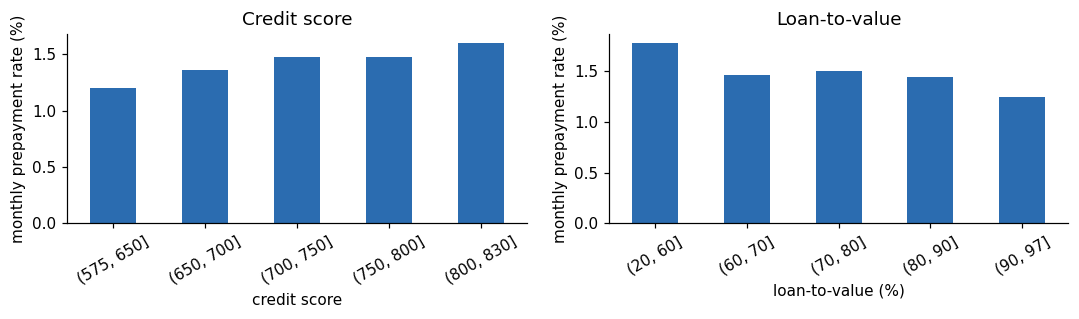

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3))
cs = prepay_rate("credit_score", [575, 650, 700, 750, 800, 830])
ltv = prepay_rate("ltv", [20, 60, 70, 80, 90, 97])
print(cs.to_string(), "\n"); print(ltv.to_string())
bar(cs, "credit score", a1).set_title("Credit score"); bar(ltv, "loan-to-value (%)", a2).set_title("Loan-to-value")
plt.tight_layout()

**Secondary effects.** Better credit slightly raises prepayment (1.20% below 650 to 1.60% above 800): these borrowers qualify for refinancing more easily. Higher loan-to-value lowers it (1.77% below 60% LTV to 1.24% above 90%): borrowers with little equity find refinancing harder. Both effects are small next to the incentive.

## 5. Categorical features

In [7]:
for c in ["occupancy_status", "loan_purpose", "channel"]:
    t = df.groupby(c).prepaid.agg(loan_months="size", prepay_rate=lambda s: round(100 * s.mean(), 2))
    print(t.rename(columns={"prepay_rate": "prepay_rate_%"}).to_string(), "\n")

                  loan_months  prepay_rate_%
occupancy_status                            
I                       19701           1.22
P                      174141           1.49
S                        7069           1.60 

              loan_months  prepay_rate_%
loan_purpose                            
C                   41369           1.42
N                   74440           1.54
P                   85102           1.42 

         loan_months  prepay_rate_%
channel                            
B              38851           1.51
C              62689           1.45
R              99371           1.46 



Investment properties (`I`) prepay least (1.22% vs 1.49% for primary residences) and no-cash-out refinances (`N`) prepay most (1.54%). The origination **channel** makes essentially no difference (1.45% to 1.51%), so a good model should give it little weight.

## 6. Correlated features

Most correlated feature pairs:
loan_age               months_to_maturity      -1.000
orig_interest_rate     current_interest_rate    1.000
ltv                    cltv                     0.998
orig_upb               current_upb              0.922
orig_interest_rate     mtg_rate                 0.801
current_interest_rate  mtg_rate                 0.801
mtg_rate               rate_incentive          -0.562


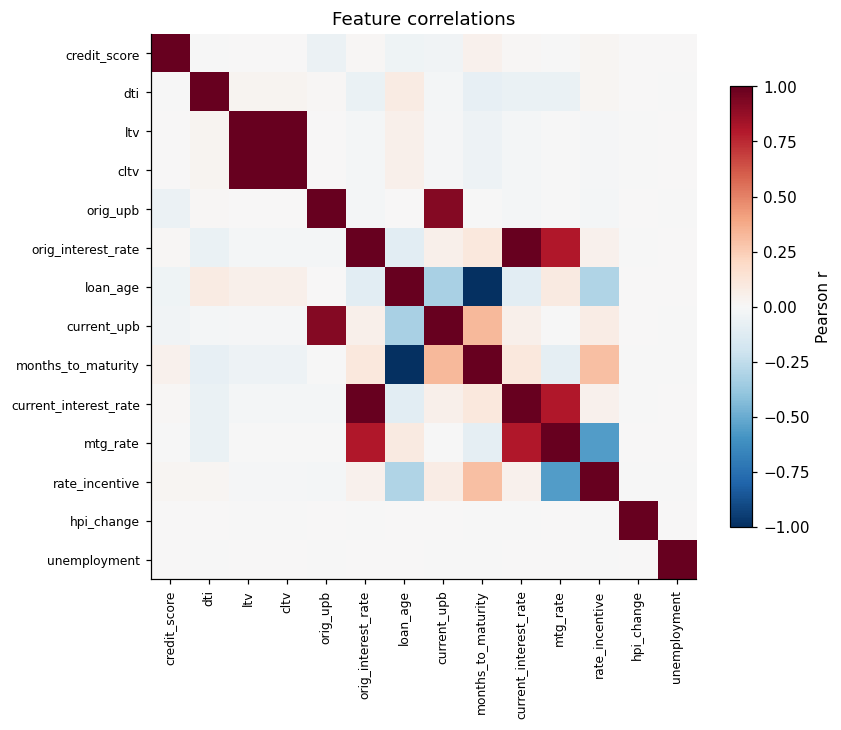

In [8]:
corr = df[NUM].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM)), NUM, rotation=90, fontsize=8); ax.set_yticks(range(len(NUM)), NUM, fontsize=8)
fig.colorbar(im, ax=ax, shrink=.8, label="Pearson r"); ax.set_title("Feature correlations")

pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print("Most correlated feature pairs:")
print(pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).round(3).to_string())

**Several features are near-duplicates:**

| Pair | r | Why |
|---|---|---|
| `loan_age` / `months_to_maturity` | -1.000 | both 30-year loans: one is 360 minus the other |
| `orig_interest_rate` / `current_interest_rate` | 1.000 | fixed-rate mortgages never change rate |
| `ltv` / `cltv` | 0.998 | few loans have a second lien |
| `orig_upb` / `current_upb` | 0.922 | balances amortise slowly |

**What this means for the models:**
- **GDA (Quadratic)** estimates a separate covariance matrix per class; with perfectly correlated features those matrices are singular. That is why QDA needs `reg_param` shrinkage: in `src/tune.py`, QDA with `reg_param=0` collapses to a validation PR-AUC of 0.023, and more shrinkage keeps helping.
- **L1 logistic** keeps one feature from each redundant group and zeroes the other: on this data it zeroes `ltv`, `orig_upb` and `mtg_rate` (their information is already in `cltv`, `current_upb` and `rate_incentive`).
- **Unregularised logistic** still predicts well, but its individual coefficients on duplicated features are unstable; L2 regularisation stabilises them.

## Key takeaways
1. The task is a rare-event problem (1:67): judge models by PR-AUC and F1, never by accuracy.
2. The refinancing incentive dominates; credit score, LTV, occupancy and purpose add small effects; channel adds almost nothing.
3. Loan age matters in a non-linear way: a seasoning ramp in the first 2-3 years, then burnout, which is mostly the incentive effect in disguise.
4. Redundant features explain why QDA needs shrinkage and why L1 prunes features.